# 1. Install Dependencies and Setup

In [ ]:
#1
!pip install -U tensorflow opencv-python matplotlib

In [ ]:
#2
!pip list

Package                               Version
------------------------------------- -------------------
absl-py                               1.4.0
accelerate                            1.15.0
access                                1.1.10.post3
affine                                3.0.1
aiofiles                              25.1.0
aiohappyeyeballs                      2.7.1
aiohttp                               3.14.3
aiosignal                             1.4.0
aiosqlite                             0.22.1
alabaster                             1.0.0
albucore                              0.0.24
albumentations                        2.0.8
ale-py                                0.12.1
altair                                5.5.0
annotated-doc                         0.0.5
annotated-types                       0.8.0
antlr4-python3-runtime                4.9.3
anyio                                 4.15.1
anywidget                             0.9.21
apsw                                  3.53.4.

In [ ]:
#3
import tensorflow as tf
import os

In [ ]:
#4
#Avoid OOM errors by setting GPU Memory Consumption Growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

In [ ]:
#5
tf.config.list_physical_devices('GPU')

[]

# 2. Remove dodgy images

In [ ]:
#7
import cv2
from PIL import Image

In [ ]:
#8
data_dir = 'data'

In [ ]:
#9
os.listdir(data_dir)

['happy', 'sad']

In [ ]:
#10
image_exts = ['jpeg','jpg', 'bmp', 'png']

In [ ]:
#11
for image_class in os.listdir(data_dir):
    for image in os.listdir(os.path.join(data_dir, image_class)):
        image_path = os.path.join(data_dir, image_class, image)
        try:
            # Try to open the image with Pillow to get its format
            with Image.open(image_path) as img_pil:
                # Get the format and convert to lowercase for consistent comparison
                img_format = img_pil.format.lower()

            # Check if the image format is in the allowed extensions list
            if img_format not in image_exts:
                print('Image not in ext list ({}): {}'.format(img_format, image_path))
                os.remove(image_path)
        except (IOError, OSError) as e:
            # Handle cases where Pillow cannot open the file (e.g., corrupt or not an image)
            print('Issue with image (corrupt or invalid format): {} - {}'.format(image_path, e))
            # Optionally remove the problematic file, depending on desired behavior
            os.remove(image_path)
        except Exception as e:
            # Catch any other unexpected errors
            print('Unexpected issue with image {}: {}'.format(image_path, e))
            # os.remove(image_path) # Uncomment to remove on any exception

# 3. Load Data

In [ ]:
#12
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
#13
data = tf.keras.utils.image_dataset_from_directory('data')

Found 305 files belonging to 2 classes.


In [ ]:
#14
data_iterator = data.as_numpy_iterator()

In [ ]:
#15
batch = data_iterator.next()

In [ ]:
batch

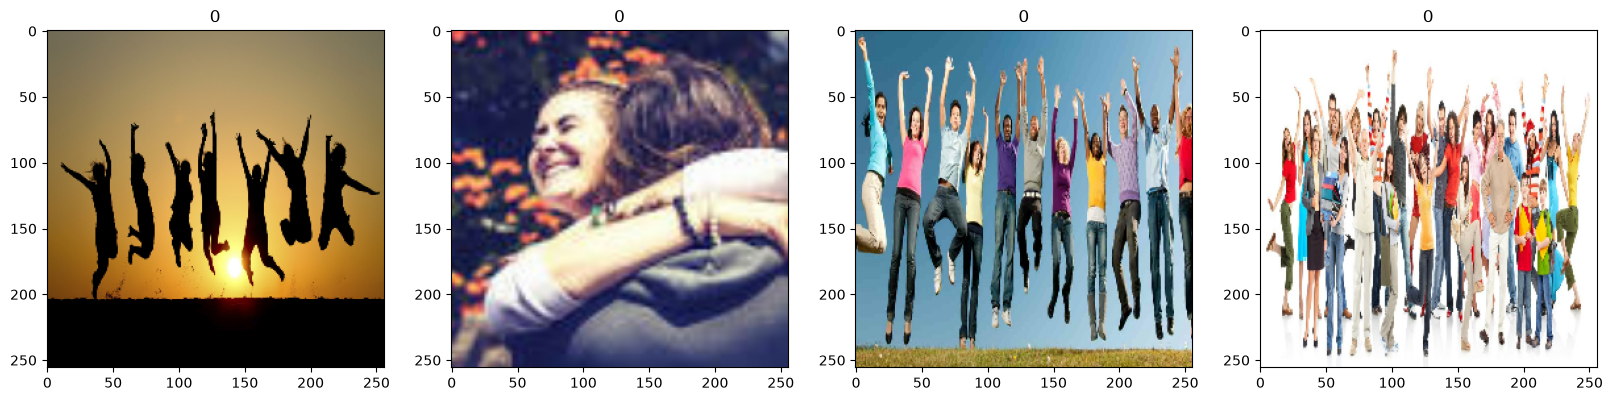

In [ ]:
#16
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
for idx, img in enumerate(batch[0][:4]):
    ax[idx].imshow(img.astype(int))
    ax[idx].title.set_text(batch[1][idx])

# 4. Scale Data

In [ ]:
#17
data = data.map(lambda x,y: (x/255, y))

In [ ]:
#18
scaled_iterator = data.as_numpy_iterator()

In [ ]:
#19
batch = scaled_iterator.next()

In [ ]:
#20
batch[0].min()

np.float32(0.0)

# 5. Split Data

In [ ]:
#21
len(data)

10

In [ ]:
#22
train_size = int(len(data)*.7)+1
val_size = int(len(data)*.2)+1
test_size = int(len(data)*.1)+1

In [ ]:
#23
train_size+val_size+test_size

10

In [ ]:
#24
train = data.take(train_size)
val = data.skip(train_size).take(val_size)
test = data.skip(train_size+val_size).take(test_size)

# 6. Build Deep Learning Model

In [ ]:
#25
train

<_TakeDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [ ]:
#26
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dense, Flatten, Dropout

In [ ]:
#27
model = Sequential()

In [ ]:
#28
model.add(Conv2D(16, (3,3), 1, activation='relu', input_shape=(256,256,3)))
model.add(MaxPooling2D())

model.add(Conv2D(32, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())

model.add(Conv2D(16, (3,3), 1, activation='relu'))
model.add(MaxPooling2D())

model.add(Flatten())

model.add(Dense(256, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
#29
model.compile('adam', loss=tf.losses.BinaryCrossentropy(), metrics=['accuracy'])

In [ ]:
#30
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 14400)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     3,686,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,696,625 (14.10 MB)

 Trainable params: 3,696,625 (14.10 MB)

 Non-trainable params: 0 (0.00 B)

# 7. Train

In [ ]:
#31
logdir='logs'

In [ ]:
#32
tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=logdir)

In [ ]:
#33
hist = model.fit(train, epochs=20, validation_data=val, callbacks=[tensorboard_callback])

Epoch 1/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 30s 3s/step - accuracy: 0.5580 - loss: 1.3969 - val_accuracy: 0.5625 - val_loss: 0.6756
Epoch 2/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 22s 3s/step - accuracy: 0.5536 - loss: 0.6809 - val_accuracy: 0.5469 - val_loss: 0.6756
Epoch 3/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - accuracy: 0.5089 - loss: 0.6711 - val_accuracy: 0.6719 - val_loss: 0.6446
Epoch 4/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.6741 - loss: 0.6109 - val_accuracy: 0.5625 - val_loss: 0.6847
Epoch 5/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.6786 - loss: 0.6180 - val_accuracy: 0.7969 - val_loss: 0.4590
Epoch 6/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 20s 3s/step - accuracy: 0.8036 - loss: 0.5199 - val_accuracy: 0.9688 - val_loss: 0.4432
Epoch 7/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.8214 - loss: 0.4152 - val_accuracy: 0.8906 - val_loss: 0.3488
Epoch 8/20
7/7 ━━━━━━━━━━━━━━━━━━━━ 21s 3s/step - accuracy: 0.8393 - loss: 0.3721 - val_accuracy: 0.8281 - val_loss: 0.3523
Epoch 9/

# 8. Plot Performance

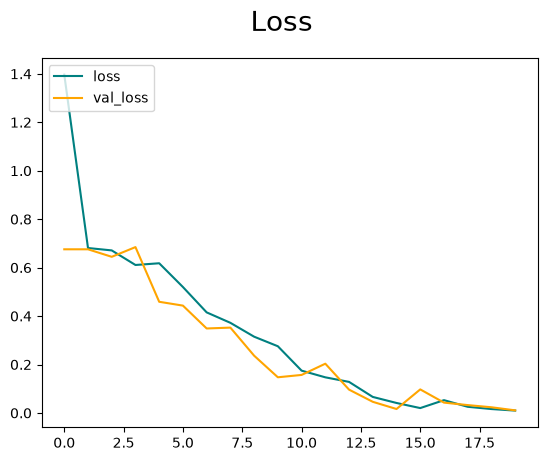

In [ ]:
#34
fig = plt.figure()
plt.plot(hist.history['loss'], color='teal', label='loss')
plt.plot(hist.history['val_loss'], color='orange', label='val_loss')
fig.suptitle('Loss', fontsize=20)
plt.legend(loc="upper left")
plt.show()

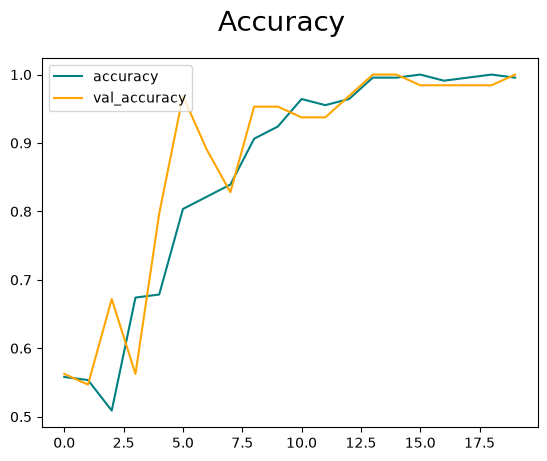

In [ ]:
#35
fig = plt.figure()
plt.plot(hist.history['accuracy'], color='teal', label='accuracy')
plt.plot(hist.history['val_accuracy'], color='orange', label='val_accuracy')
fig.suptitle('Accuracy', fontsize=20)
plt.legend(loc="upper left")
plt.show()

# 9. Evaluate

In [ ]:
#36
from tensorflow.keras.metrics import Precision, Recall, BinaryAccuracy

In [ ]:
#37
pre = Precision()
re = Recall()
acc = BinaryAccuracy()

In [ ]:
#38
for batch in val.as_numpy_iterator():
    X, y = batch
    yhat = model.predict(X)
    pre.update_state(y, yhat)
    re.update_state(y, yhat)
    acc.update_state(y, yhat)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step


In [ ]:
#39
print(f'Precision: {pre.result().numpy()}, Recall: {re.result().numpy()}, Accuracy: {acc.result().numpy()}')

Precision: 1.0, Recall: 1.0, Accuracy: 1.0


# 10. Test

In [ ]:
#40
import cv2

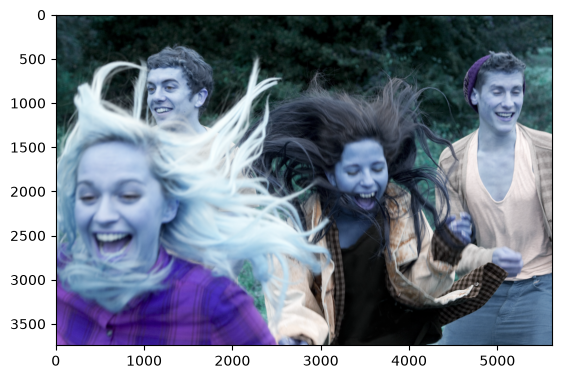

In [ ]:
#41
img = cv2.imread('154006829.jpg')
plt.imshow(img)
plt.show()

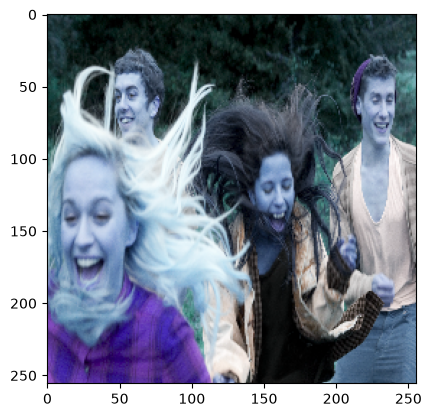

In [ ]:
#42
resize = tf.image.resize(img, (256,256))
plt.imshow(resize.numpy().astype(int))
plt.show()

In [ ]:
#43
yhat = model.predict(np.expand_dims(resize/255, 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step


In [ ]:
#44
yhat

array([[0.04635346]], dtype=float32)

In [ ]:
#45
if yhat > 0.5:
    print(f'Predicted class is Sad')
else:
    print(f'Predicted class is Happy')

Predicted class is Happy


# 11. Save the Model

In [ ]:
#46
from tensorflow.keras.models import load_model

In [ ]:
#47
model.save(os.path.join('models','imageclassifier.h5'))

In [ ]:
#48
new_model = load_model(os.path.join('models','imageclassifier.h5'))

In [ ]:
#49
new_model.predict(np.expand_dims(resize/255, 0))

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 610ms/step


array([[0.04635346]], dtype=float32)